# 01 — Feature Inventory

**Purpose:** establish integrity, coverage, missingness, and the basic statistical profile of the model-facing feature dataset before regime modeling.

This notebook:
- opens `research.duckdb` in **read-only** mode;
- treats `time_series_feature_state` as the primary model-facing dataset;
- inspects the long-form option and L2-distribution tables when available;
- checks duplicates, temporal continuity, readiness coverage, missingness, infinities, constants, and extreme values;
- does **not** standardize, winsorize, impute, or mutate data.

> Research rule: notebooks discover; production Python modules implement accepted transformations.

## 1. Environment and read-only database connection

In [1]:
from pathlib import Path
import os
import math
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 180)

load_dotenv()

data_root_env = os.getenv("DERIBIT_DATA_ROOT")
if not data_root_env:
    raise RuntimeError("DERIBIT_DATA_ROOT is not defined in the environment/.env file.")

DATA_ROOT = Path(data_root_env).expanduser().resolve()
DB_PATH = DATA_ROOT / "database" / "research.duckdb"

if not DB_PATH.exists():
    raise FileNotFoundError(f"Research database not found: {DB_PATH}")

con = duckdb.connect(str(DB_PATH), read_only=True)

print(f"Research DB: {DB_PATH}")
print("Connection mode: read-only")

Research DB: D:\MarketData\Deribit\database\research.duckdb
Connection mode: read-only


## 2. Feature-layer relation inventory

In [2]:
relations = con.execute(
    """
    SELECT table_schema, table_name, table_type
    FROM information_schema.tables
    WHERE table_schema NOT IN ('information_schema', 'pg_catalog')
    ORDER BY table_schema, table_name
    """
).df()

feature_relations = [
    "time_series_feature_state",
    "option_surface_feature_state",
    "primary_option_surface_feature_state",
    "l2_instability_distribution_state",
]

display(relations[relations["table_name"].isin(feature_relations)].reset_index(drop=True))

missing_relations = [name for name in feature_relations if name not in set(relations["table_name"])]
print("Missing relations:" if missing_relations else "All expected feature-layer relations are present.", missing_relations)

,table_schema,table_name,table_type
0,main,l2_instability_distribution_state,BASE TABLE
1,main,option_surface_feature_state,BASE TABLE
2,main,primary_option_surface_feature_state,BASE TABLE
3,main,time_series_feature_state,BASE TABLE


All expected feature-layer relations are present. []


## 3. Load the model-facing state table

Expected grain: **one row = one underlying × one 5-minute state**.

In [3]:
features = con.execute(
    """
    SELECT *
    FROM time_series_feature_state
    ORDER BY state_time, underlying
    """
).df()

print(f"Rows:    {len(features):,}")
print(f"Columns: {features.shape[1]:,}")
display(features.head())

Rows:    28,224
Columns: 148


,state_id,state_time,underlying,session_id,expiry_date,session_start,session_end,minutes_to_expiry,is_opening_state,minutes_since_session_start,session_progress_fraction,collection_complete,price_features_ready,state_research_ready,l2_boundary_ready,l2_intrawindow_ready,futures_instrument_name,futures_tradable_mid_price,futures_mark_price,futures_index_price,futures_underlying_price,market_reference_price,market_reference_source,market_reference_is_tradable,futures_spread_bps,perpetual_mid_vs_index_bps,perpetual_mark_vs_index_bps,microprice_vs_mid_bps,return_input_eligible,open,high,low,close,vwap,volume_usd,buy_volume_usd,sell_volume_usd,trade_count,open_interest,book_stats_coverage_ms,book_stats_complete,book_update_count,book_twa_spread,book_twa_obi_5,book_twa_obi_10,book_twa_obi_20,book_twa_bid_depth_20,book_twa_ask_depth_20,book_twa_microprice,book_min_obi_20,book_max_obi_20,book_twa_abs_obi_20,book_obi_20_std,book_obi_20_path_roughness_per_min,book_obi_20_range,book_obi_20_coherence_noise,book_obi_20_transition_count,book_obi_20_raw_zero_cross_count,book_obi_20_raw_zero_cross_rate,book_obi_20_reversal_strength_mean,book_obi_20_reversal_strength_max,return_5m,return_15m,return_30m,return_1h,log1p_volume_usd,signed_volume_usd,trade_flow_imbalance,buy_volume_share,average_trade_size_usd,intrabar_range_bps,close_vs_vwap_bps,open_interest_change_5m,open_interest_return_5m,book_twa_spread_bps,book_twa_microprice_vs_reference_bps,book_twa_obi_20_change_5m,l2_instability_scalar_available,l2_coherence_available,rv_30m_return_count,rv_1h_return_count,rv_4h_return_count,realized_vol_30m,realized_vol_30m_annualized,realized_vol_1h,realized_vol_1h_annualized,realized_vol_4h,realized_vol_4h_annualized,realized_vol_30m_ready,realized_vol_1h_ready,realized_vol_4h_ready,microstructure_core_ready,l2_instability_features_ready,primary_option_family_id,primary_option_instrument_type,primary_option_settlement_currency,primary_option_api_currency,option_family_selection_reason,option_forward_price,option_iv_atm_forward,option_skew_025,option_skew_050,option_curvature_025,option_curvature_050,option_local_skew_slope_025,option_local_skew_slope_050,core_smile_quality_tier,core_smile_tight,core_smile_usable,wing_050_usable,full_grid_usable,core_max_interpolation_span,wing_050_max_interpolation_span,full_grid_max_interpolation_span,option_base_eligible_rows,option_two_sided_eligible_rows,option_median_two_sided_spread_bps,option_p90_two_sided_spread_bps,atm_iv_change_5m,atm_iv_change_15m,atm_iv_change_1h,skew_025_change_5m,skew_025_change_15m,skew_025_change_1h,curvature_025_change_5m,curvature_025_change_15m,curvature_025_change_1h,skew_050_change_5m,core_surface_change_5m_ready,iv_put_25d,iv_call_25d,rr_25d,bf_25d,iv_put_10d,iv_call_10d,rr_10d,bf_10d,delta_25d_smile_available,full_delta_smile_available,max_delta_interpolation_span,median_delta_interpolation_span,rr_25d_change_5m,bf_25d_change_5m,delta_25d_change_5m_ready,structural_level_features_ready,structural_dynamic_features_ready,microstructure_features_ready,instability_features_ready
0,AVAX|2026-09-19T08:00:00Z,2026-09-19 10:00:00+02:00,AVAX,expiry=2026-09-20,2026-09-20,2026-09-19 10:00:00+02:00,2026-09-20 10:00:00+02:00,1440,True,0,0.0,False,False,False,False,False,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,<NA>,False,False,False,False
1,BTC|2026-09-19T08:00:00Z,2026-09-19 10:00:00+02:00,BTC,expiry=2026-09-20,2026-09-20,2026-09-19 10:00:00+02:00,2026-09-20 10:00:00+02:00,1440,True,0,0.0,False,False,False,Fals

## 4. Dataset identity and coverage

In [4]:
overview = pd.Series({
    "rows": len(features),
    "columns": features.shape[1],
    "unique_state_ids": features["state_id"].nunique(dropna=True),
    "underlyings": features["underlying"].nunique(dropna=True),
    "first_state": features["state_time"].min(),
    "last_state": features["state_time"].max(),
    "first_expiry": features["expiry_date"].min(),
    "last_expiry": features["expiry_date"].max(),
}, name="value").to_frame()

display(overview)

,value
rows,28224
columns,148
unique_state_ids,28224
underlyings,7
first_state,2026-09-19 10:00:00+02:00
last_state,2026-10-03 09:55:00+02:00
first_expiry,2026-09-20 00:00:00
last_expiry,2026-10-03 00:00:00


In [5]:
asset_counts = (
    features.groupby("underlying", dropna=False)
    .agg(
        rows=("state_id", "size"),
        unique_states=("state_id", "nunique"),
        first_state=("state_time", "min"),
        last_state=("state_time", "max"),
        research_ready=("state_research_ready", lambda s: int(s.fillna(False).sum())),
    )
    .reset_index()
)
asset_counts["research_ready_pct"] = 100.0 * asset_counts["research_ready"] / asset_counts["rows"]
display(asset_counts)

,underlying,rows,unique_states,first_state,last_state,research_ready,research_ready_pct
0,AVAX,4032,4032,2026-09-19 10:00:00+02:00,2026-10-03 09:55:00+02:00,3365,83.457341
1,BTC,4032,4032,2026-09-19 10:00:00+02:00,2026-10-03 09:55:00+02:00,3365,83.457341
2,ETH,4032,4032,2026-09-19 10:00:00+02:00,2026-10-03 09:55:00+02:00,3365,83.457341
3,HYPE,4032,4032,2026-09-19 10:00:00+02:00,2026-10-03 09:55:00+02:00,3365,83.457341
4,SOL,4032,4032,2026-09-19 10:00:00+02:00,2026-10-03 09:55:00+02:00,3365,83.457341
5,TRX,4032,4032,2026-09-19 10:00:00+02:00,2026-10-03 09:55:00+02:00,3365,83.457341
6,XRP,4032,4032,2026-09-19 10:00:00+02:00,2026-10-03 09:55:00+02:00,3365,83.457341


In [6]:
expiry_counts = (
    features.groupby("expiry_date", dropna=False)
    .agg(
        rows=("state_id", "size"),
        underlyings=("underlying", "nunique"),
        research_ready=("state_research_ready", lambda s: int(s.fillna(False).sum())),
        structural_level=("structural_level_features_ready", lambda s: int(s.fillna(False).sum())),
        structural_dynamic=("structural_dynamic_features_ready", lambda s: int(s.fillna(False).sum())),
        microstructure=("microstructure_features_ready", lambda s: int(s.fillna(False).sum())),
        instability=("instability_features_ready", lambda s: int(s.fillna(False).sum())),
    )
    .reset_index()
)

for col in ["research_ready", "structural_level", "structural_dynamic", "microstructure", "instability"]:
    expiry_counts[f"{col}_pct"] = 100.0 * expiry_counts[col] / expiry_counts["rows"]

display(expiry_counts)

,expiry_date,rows,underlyings,research_ready,structural_level,structural_dynamic,microstructure,instability,research_ready_pct,structural_level_pct,structural_dynamic_pct,microstructure_pct,instability_pct
0,2026-09-20,2016,7,0,0,0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000
1,2026-09-21,2016,7,0,0,0,0,0,0.000000,0.000000,0.000000,0.000000,0.000000
2,2026-09-22,2016,7,1778,1645,1494,0,0,88.194444,81.597222,74.107143,0.000000,0.000000
3,2026-09-23,2016,7,1967,1939,1680,1890,0,97.569444,96.180556,83.333333,93.750000,0.000000
4,2026-09-24,2016,7,1988,1967,1743,1995,0,98.611111,97.569444,86.458333,98.958333,0.000000
5,2026-09-25,2016,7,1974,1939,1589,1981,0,97.916667,96.180556,78.819444,98.263889,0.000000
6,2026-09-26,2016,7,1960,1911,1386,1967,0,97.222222,94.791667,68.750000,97.569444,0.000000
7,2026-09-27,2016,7,2009,2009,2002,2016,0,99.652778,99.652778,99.305556,100.000000,0.000000
8,2026-09-28,2016,7,2009,2009,2002,2016,0,99.652778,99.652778,99.305556,100.000000,0.000000
9,2026-09-29,2016,7,1953,1918,1582,1960,0,96.875000,95.138889,78.472222,97.222222,0.000000


## 5. Uniqueness checks

In [7]:
duplicate_state_ids = int(features["state_id"].duplicated().sum())
duplicate_underlying_times = int(features.duplicated(subset=["underlying", "state_time"]).sum())

print(f"Duplicate state_id rows:               {duplicate_state_ids:,}")
print(f"Duplicate underlying × timestamp rows: {duplicate_underlying_times:,}")

assert duplicate_state_ids == 0
assert duplicate_underlying_times == 0

Duplicate state_id rows:               0
Duplicate underlying × timestamp rows: 0


## 6. Column inventory and dtypes

In [8]:
dtype_inventory = pd.DataFrame({
    "column": features.columns,
    "dtype": [str(features[c].dtype) for c in features.columns],
    "non_null": [int(features[c].notna().sum()) for c in features.columns],
    "null": [int(features[c].isna().sum()) for c in features.columns],
    "unique": [int(features[c].nunique(dropna=True)) for c in features.columns],
})
dtype_inventory["missing_pct"] = 100.0 * dtype_inventory["null"] / len(features)
display(dtype_inventory)

,column,dtype,non_null,null,unique,missing_pct
0,state_id,str,28224,0,28224,0.000000
1,state_time,"datetime64[us, Europe/Madrid]",28224,0,4032,0.000000
2,underlying,str,28224,0,7,0.000000
3,session_id,str,28224,0,14,0.000000
4,expiry_date,datetime64[us],28224,0,14,0.000000
5,session_start,"datetime64[us, Europe/Madrid]",28224,0,14,0.000000
6,session_end,"datetime64[us, Europe/Madrid]",28224,0,14,0.000000
7,minutes_to_expiry,int64,28224,0,288,0.000000
8,is_opening_state,bool,28224,0,2,0.000000
9,minutes_since_session_start,int64,28224,0,288,0.000000


## 7. Missingness profile

Missingness is not automatically a defect: it can encode pre-collector history, readiness failures, sparse option wings/delta points, rolling-window warm-up, or intentional non-backfill of new L2 statistics.

In [9]:
missingness = pd.DataFrame({
    "column": features.columns,
    "missing": [int(features[c].isna().sum()) for c in features.columns],
    "available": [int(features[c].notna().sum()) for c in features.columns],
})
missingness["missing_pct"] = 100.0 * missingness["missing"] / len(features)
missingness = missingness.sort_values(["missing_pct", "column"], ascending=[False, True]).reset_index(drop=True)
display(missingness)

,column,missing,available,missing_pct
0,futures_underlying_price,28224,0,100.000000
1,book_obi_20_reversal_strength_max,24519,3705,86.872874
2,book_obi_20_reversal_strength_mean,24519,3705,86.872874
3,book_obi_20_coherence_noise,24430,3794,86.557540
4,book_obi_20_path_roughness_per_min,24430,3794,86.557540
5,book_obi_20_range,24430,3794,86.557540
6,book_obi_20_raw_zero_cross_count,24430,3794,86.557540
7,book_obi_20_raw_zero_cross_rate,24430,3794,86.557540
8,book_obi_20_std,24430,3794,86.557540
9,book_obi_20_transition_count,24430,3794,86.557540


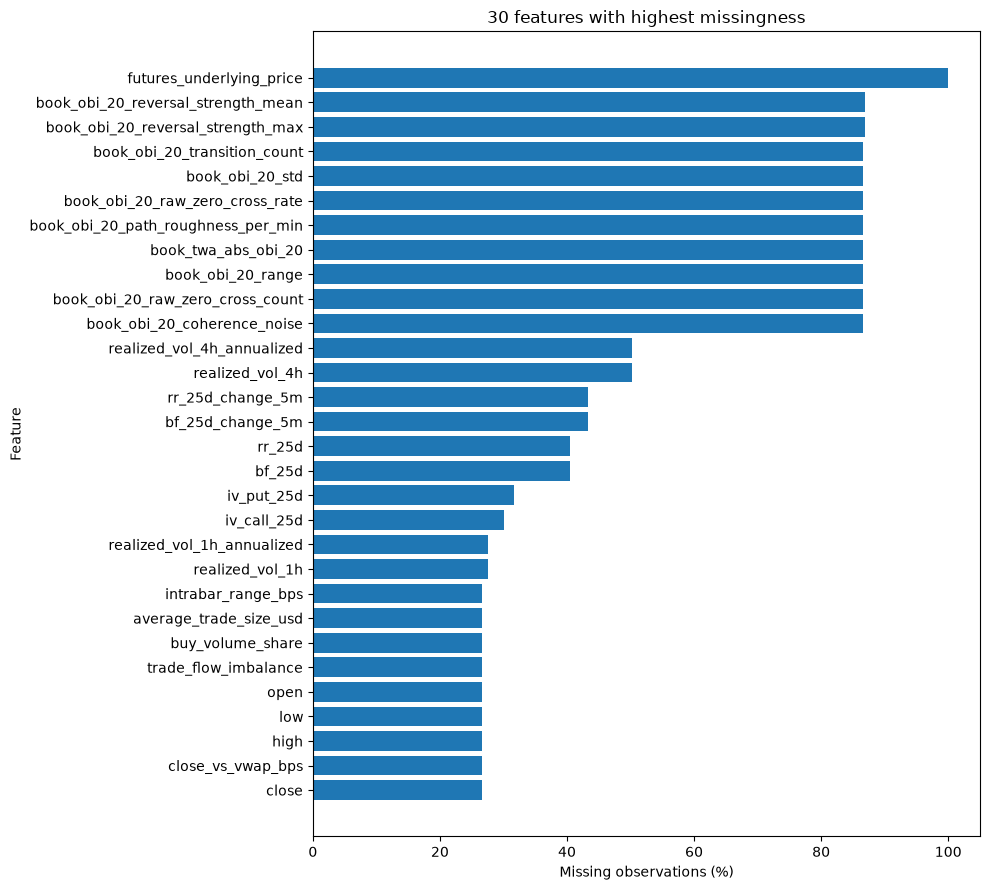

In [10]:
top_missing = missingness.head(30).sort_values("missing_pct")
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(top_missing["column"], top_missing["missing_pct"])
ax.set_xlabel("Missing observations (%)")
ax.set_ylabel("Feature")
ax.set_title("30 features with highest missingness")
plt.tight_layout()
plt.show()

## 8. Readiness coverage

In [11]:
readiness_columns = [c for c in [
    "collection_complete",
    "price_features_ready",
    "state_research_ready",
    "l2_boundary_ready",
    "l2_intrawindow_ready",
    "realized_vol_30m_ready",
    "realized_vol_1h_ready",
    "realized_vol_4h_ready",
    "core_smile_usable",
    "core_surface_change_5m_ready",
    "delta_25d_smile_available",
    "delta_25d_change_5m_ready",
    "structural_level_features_ready",
    "structural_dynamic_features_ready",
    "microstructure_features_ready",
    "instability_features_ready",
] if c in features.columns]

readiness_summary = []
for col in readiness_columns:
    true_count = int(features[col].fillna(False).sum())
    readiness_summary.append({
        "flag": col,
        "true": true_count,
        "false_or_null": len(features) - true_count,
        "coverage_pct": 100.0 * true_count / len(features),
    })

readiness_summary = pd.DataFrame(readiness_summary).sort_values("coverage_pct", ascending=False).reset_index(drop=True)
display(readiness_summary)

,flag,true,false_or_null,coverage_pct
0,collection_complete,23954,4270,84.871032
1,price_features_ready,23625,4599,83.705357
2,state_research_ready,23555,4669,83.457341
3,core_smile_usable,23436,4788,83.035714
4,structural_level_features_ready,23128,5096,81.944444
5,core_surface_change_5m_ready,23033,5191,81.607851
6,l2_boundary_ready,22064,6160,78.174603
7,realized_vol_30m_ready,21910,6314,77.628968
8,l2_intrawindow_ready,21756,6468,77.083333
9,microstructure_features_ready,21756,6468,77.083333


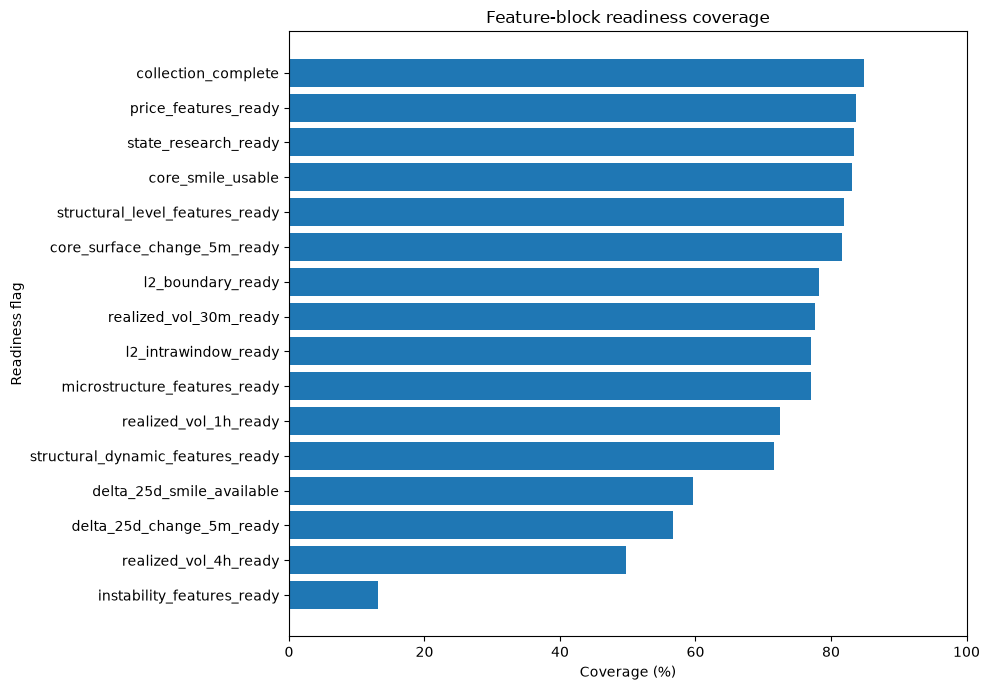

In [12]:
fig, ax = plt.subplots(figsize=(10, 7))
ordered_flags = readiness_summary.sort_values("coverage_pct")
ax.barh(ordered_flags["flag"], ordered_flags["coverage_pct"])
ax.set_xlim(0, 100)
ax.set_xlabel("Coverage (%)")
ax.set_ylabel("Readiness flag")
ax.set_title("Feature-block readiness coverage")
plt.tight_layout()
plt.show()

## 9. Numeric features, infinities, and quantiles

In [13]:
numeric_columns = features.select_dtypes(include=[np.number]).columns.tolist()
boolean_columns = [c for c in features.columns if str(features[c].dtype) in {"bool", "boolean"}]
numeric_feature_columns = [c for c in numeric_columns if c not in boolean_columns]

print(f"Numeric columns:         {len(numeric_columns)}")
print(f"Numeric feature columns: {len(numeric_feature_columns)}")
print(f"Boolean columns:         {len(boolean_columns)}")

Numeric columns:         105
Numeric feature columns: 105
Boolean columns:         28


In [14]:
infinity_rows = []
for col in numeric_feature_columns:
    arr = pd.to_numeric(features[col], errors="coerce").to_numpy(dtype=float, na_value=np.nan)
    pos_inf = int(np.isposinf(arr).sum())
    neg_inf = int(np.isneginf(arr).sum())
    if pos_inf or neg_inf:
        infinity_rows.append({"column": col, "positive_inf": pos_inf, "negative_inf": neg_inf})

infinity_summary = pd.DataFrame(infinity_rows, columns=["column", "positive_inf", "negative_inf"])
print(f"Columns containing ±inf: {len(infinity_summary)}")
display(infinity_summary)

Columns containing ±inf: 0


,column,positive_inf,negative_inf


In [15]:
quantiles = [0.001, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]
summary_rows = []

for col in numeric_feature_columns:
    s = pd.to_numeric(features[col], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    row = {
        "column": col,
        "n": len(s),
        "missing_pct": 100.0 * (len(features) - len(s)) / len(features),
    }
    if len(s):
        row.update({"mean": s.mean(), "std": s.std(), "min": s.min(), "max": s.max()})
        for q, value in s.quantile(quantiles).items():
            row[f"q_{q:g}"] = value
    summary_rows.append(row)

numeric_summary = pd.DataFrame(summary_rows)
display(numeric_summary)

,column,n,missing_pct,mean,std,min,max,q_0.001,q_0.01,q_0.05,q_0.25,q_0.5,q_0.75,q_0.95,q_0.99,q_0.999
0,minutes_to_expiry,28224,0.000000,7.225000e+02,4.156971e+02,5.000000e+00,1.440000e+03,5.000000e+00,15.000000,75.000000,363.750000,722.500000,1.081250e+03,1.370000e+03,1.430000e+03,1.440000e+03
1,minutes_since_session_start,28224,0.000000,7.175000e+02,4.156971e+02,0.000000e+00,1.435000e+03,0.000000e+00,10.000000,70.000000,358.750000,717.500000,1.076250e+03,1.365000e+03,1.425000e+03,1.435000e+03
2,session_progress_fraction,28224,0.000000,4.982639e-01,2.886785e-01,0.000000e+00,9.965278e-01,0.000000e+00,0.006944,0.048611,0.249132,0.498264,7.473958e-01,9.479167e-01,9.895833e-01,9.965278e-01
3,futures_tradable_mid_price,23940,15.178571,1.248931e+04,2.941694e+04,3.317900e-01,8.729200e+04,3.325100e-01,0.333620,0.335150,1.539238,91.648750,2.679665e+03,8.458246e+04,8.638796e+04,8.689712e+04
4,futures_mark_price,23940,15.178571,1.248943e+04,2.941722e+04,3.317270e-01,8.730491e+04,3.325104e-01,0.333636,0.335169,1.539300,91.651000,2.679673e+03,8.458286e+04,8.639177e+04,8.689141e+04
5,futures_index_price,23940,15.178571,1.248604e+04,2.940925e+04,3.322420e-01,8.727324e+04,3.327066e-01,0.333650,0.335223,1.538700,91.571500,2.679070e+03,8.456683e+04,8.635860e+04,8.686862e+04
6,futures_underlying_price,0,100.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,market_reference_price,23940,15.178571,1.248931e+04,2.941694e+04,3.317900e-01,8.729200e+04,3.325100e-01,0.333620,0.335150,1.539238,91.648750,2.679665e+03,8.458246e+04,8.638796e+04,8.689712e+04
8,futures_spread_bps,23940,15.178571,2.716484e+00,2.122895e+01,1.146448e-02,2.139638e+03,1.151710e-02,0.011584,0.011832,0.037432,1.267668,3.247195e+00,5.987316e+00,8.090017e+00,3.289275e+02
9,perpetual_mid_vs_index_bps,23940,15.178571,2.960438e+00,9.257668e+00,-8.796532e+01,1.012713e+03,-3.043845e+01,-6.192289,-1.926174,1.465010,2.752546,4.174622e+00,7.643632e+00,1.076134e+01,5.217988e+01


## 10. Constant and near-constant features

`dominant_share` is the fraction of non-null observations occupied by the most frequent value.

In [16]:
constant_rows = []
for col in features.columns:
    s = features[col].dropna()
    if len(s) == 0:
        constant_rows.append({"column": col, "non_null": 0, "unique": 0, "dominant_share": np.nan, "status": "all_missing"})
        continue
    counts = s.value_counts(dropna=True)
    unique = int(len(counts))
    dominant_share = float(counts.iloc[0] / len(s))
    status = None
    if unique == 1:
        status = "constant"
    elif dominant_share >= 0.995:
        status = "near_constant"
    if status:
        constant_rows.append({"column": col, "non_null": len(s), "unique": unique, "dominant_share": dominant_share, "status": status})

constant_summary = pd.DataFrame(constant_rows)
if not constant_summary.empty:
    constant_summary = constant_summary.sort_values(["status", "dominant_share"], ascending=[True, False], na_position="last").reset_index(drop=True)
display(constant_summary)

,column,non_null,unique,dominant_share,status
0,futures_underlying_price,0,0,NaN,all_missing
1,market_reference_source,23940,1,1.000000,constant
2,market_reference_is_tradable,23940,1,1.000000,constant
3,primary_option_instrument_type,25718,1,1.000000,constant
4,primary_option_settlement_currency,25718,1,1.000000,constant
5,primary_option_api_currency,25718,1,1.000000,constant
6,option_family_selection_reason,25718,1,1.000000,constant
7,is_opening_state,28224,2,0.996528,near_constant


## 11. Temporal continuity

The canonical grid should preserve expected 5-minute timestamps. This verifies that the time index itself has not developed irregular gaps.

In [17]:
ordered = features[["underlying", "state_time", "state_id"]].sort_values(["underlying", "state_time"]).copy()
ordered["delta_minutes"] = ordered.groupby("underlying")["state_time"].diff().dt.total_seconds().div(60.0)
irregular = ordered[ordered["delta_minutes"].notna() & (ordered["delta_minutes"] != 5.0)]

gap_summary = (
    irregular.groupby("underlying")
    .agg(
        irregular_intervals=("delta_minutes", "size"),
        min_gap_minutes=("delta_minutes", "min"),
        max_gap_minutes=("delta_minutes", "max"),
    )
    .reset_index()
)

print(f"Irregular asset-level timestamp intervals: {len(irregular):,}")
display(gap_summary)

Irregular asset-level timestamp intervals: 0


,underlying,irregular_intervals,min_gap_minutes,max_gap_minutes


## 12. Feature availability by asset

In [18]:
candidate_features = [c for c in [
    "return_5m",
    "realized_vol_1h",
    "option_iv_atm_forward",
    "option_skew_025",
    "option_curvature_025",
    "atm_iv_change_5m",
    "skew_025_change_5m",
    "curvature_025_change_5m",
    "rr_25d",
    "bf_25d",
    "book_twa_obi_20",
    "book_obi_20_std",
    "book_obi_20_path_roughness_per_min",
    "book_obi_20_coherence_noise",
] if c in features.columns]

availability_by_asset = []
for asset, group in features.groupby("underlying"):
    row = {"underlying": asset, "rows": len(group)}
    for col in candidate_features:
        row[f"{col}_pct"] = 100.0 * group[col].notna().mean()
    availability_by_asset.append(row)

availability_by_asset = pd.DataFrame(availability_by_asset).sort_values("underlying")
display(availability_by_asset)

,underlying,rows,return_5m_pct,realized_vol_1h_pct,option_iv_atm_forward_pct,option_skew_025_pct,option_curvature_025_pct,atm_iv_change_5m_pct,skew_025_change_5m_pct,curvature_025_change_5m_pct,rr_25d_pct,bf_25d_pct,book_twa_obi_20_pct,book_obi_20_std_pct,book_obi_20_path_roughness_per_min_pct,book_obi_20_coherence_noise_pct
0,AVAX,4032,82.614087,72.470238,83.457341,83.457341,83.457341,82.043651,82.043651,82.043651,75.620040,75.620040,78.199405,13.44246,13.44246,13.44246
1,BTC,4032,82.614087,72.470238,83.457341,83.457341,83.457341,82.043651,82.043651,82.043651,52.703373,52.703373,78.199405,13.44246,13.44246,13.44246
2,ETH,4032,82.614087,72.470238,83.457341,83.457341,83.457341,82.043651,82.043651,82.043651,60.292659,60.292659,78.199405,13.44246,13.44246,13.44246
3,HYPE,4032,82.614087,72.470238,83.457341,83.457341,83.457341,82.043651,82.043651,82.043651,66.418651,66.418651,78.199405,13.44246,13.44246,13.44246
4,SOL,4032,82.614087,72.470238,83.457341,83.457341,83.457341,82.043651,82.043651,82.043651,72.147817,72.147817,78.199405,13.44246,13.44246,13.44246
5,TRX,4032,82.614087,72.470238,83.457341,83.457341,83.457341,82.043651,82.043651,82.043651,23.710317,23.710317,78.199405,13.44246,13.44246,13.44246
6,XRP,4032,82.614087,72.470238,83.085317,80.505952,80.505952,78.993056,78.993056,78.993056,66.071429,66.071429,78.199405,13.44246,13.44246,13.44246


## 13. Core distribution snapshot

This is only a first look. Dedicated notebooks will examine transformations, ECDFs, tails, autocorrelation, conditioning, and cross-feature relationships.

In [19]:
distribution_features = [c for c in [
    "return_5m",
    "realized_vol_1h_annualized",
    "log1p_volume_usd",
    "trade_flow_imbalance",
    "futures_spread_bps",
    "perpetual_mid_vs_index_bps",
    "book_twa_obi_20",
    "option_iv_atm_forward",
    "option_skew_025",
    "option_curvature_025",
    "atm_iv_change_5m",
] if c in features.columns]

distribution_snapshot = numeric_summary[numeric_summary["column"].isin(distribution_features)].set_index("column").reindex(distribution_features).reset_index()
display(distribution_snapshot)

,column,n,missing_pct,mean,std,min,max,q_0.001,q_0.01,q_0.05,q_0.25,q_0.5,q_0.75,q_0.95,q_0.99,q_0.999
0,return_5m,23317,17.385913,-0.000006,0.002233,-0.096015,0.096277,-0.012791,-0.005798,-0.002977,-0.000785,0.000000,0.000767,0.003063,0.005687,0.012219
1,realized_vol_1h_annualized,20454,27.529762,0.534707,0.486876,0.013913,12.727640,0.036352,0.062086,0.098181,0.249721,0.440173,0.708983,1.218453,1.909759,3.803325
2,log1p_volume_usd,23961,15.104167,8.528995,4.158616,0.000000,18.381071,0.000000,0.000000,0.000000,6.913616,9.585002,11.318526,13.739275,15.083348,16.062472
3,trade_flow_imbalance,20694,26.679422,-0.015416,0.652006,-1.000000,1.000000,-1.000000,-1.000000,-1.000000,-0.549026,-0.003459,0.485461,1.000000,1.000000,1.000000
4,futures_spread_bps,23940,15.178571,2.716484,21.228951,0.011464,2139.637859,0.011517,0.011584,0.011832,0.037432,1.267668,3.247195,5.987316,8.090017,328.927522
5,perpetual_mid_vs_index_bps,23940,15.178571,2.960438,9.257668,-87.965324,1012.713340,-30.438449,-6.192289,-1.926174,1.465010,2.752546,4.174622,7.643632,10.761341,52.179879
6,book_twa_obi_20,22071,21.800595,-0.006982,0.158711,-0.807421,0.714406,-0.621508,-0.479865,-0.300645,-0.071757,0.004268,0.070182,0.221336,0.454874,0.636187
7,option_iv_atm_forward,23540,16.595805,50.047234,23.792047,8.654510,457.556512,11.373947,14.715749,19.034284,27.625109,50.002898,66.884669,90.444839,104.236202,124.108844
8,option_skew_025,23436,16.964286,3.253901,9.574723,-47.524583,379.486618,-26.283659,-16.870000,-9.019053,-0.872248,2.969283,7.097617,15.722958,25.090600,77.677750
9,option_curvature_025,23436,16.964286,9.068966,8.427207,-416.786227,198.451851,-10.746215,-1.300563,0.939507,3.651653,7.583239,13.127418,21.978410,33.365951,58.624896


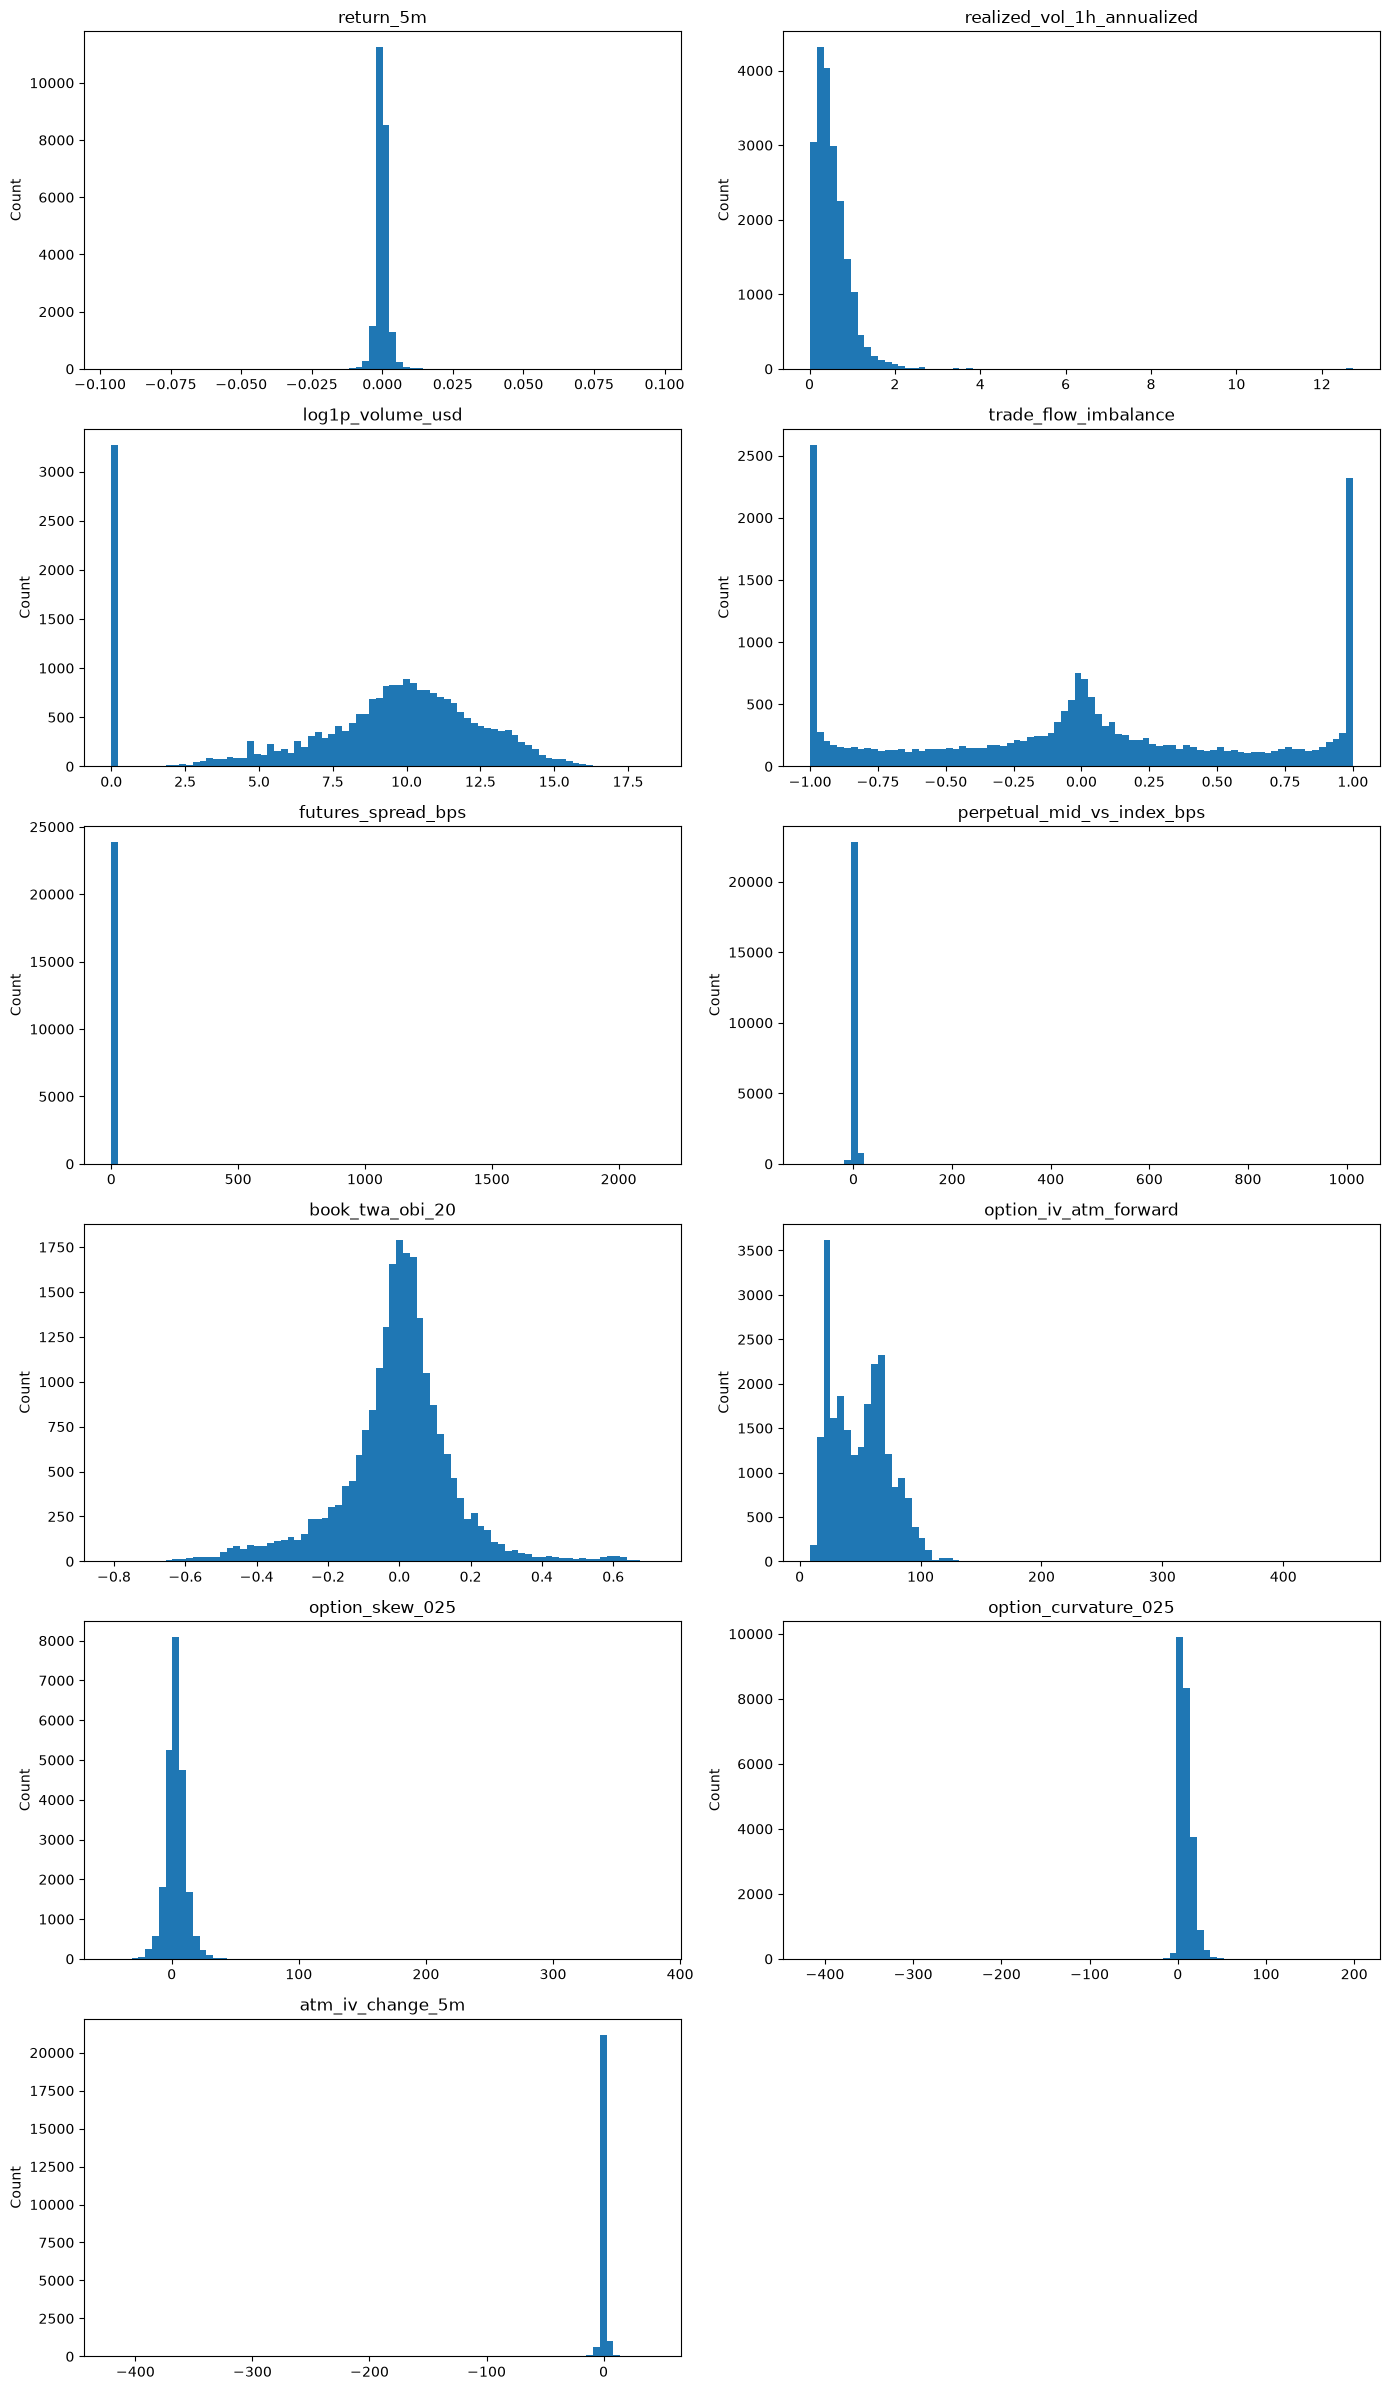

In [20]:
if distribution_features:
    ncols = 2
    nrows = math.ceil(len(distribution_features) / ncols)
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 4 * nrows))
    axes = np.atleast_1d(axes).ravel()

    for ax, col in zip(axes, distribution_features):
        s = pd.to_numeric(features[col], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
        if len(s):
            ax.hist(s, bins=80)
            ax.set_title(col)
            ax.set_ylabel("Count")
        else:
            ax.text(0.5, 0.5, "No available observations", ha="center", va="center")
            ax.set_title(col)

    for ax in axes[len(distribution_features):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

## 14. Option-family inventory

The final matrix uses one stable primary family, but the long-form table retains all families for robustness research.

In [21]:
if "option_surface_feature_state" in set(relations["table_name"]):
    option_family_inventory = con.execute(
        """
        SELECT
            underlying,
            option_family_id,
            COUNT(*) AS states,
            SUM(CASE WHEN core_smile_usable THEN 1 ELSE 0 END) AS core_usable,
            SUM(CASE WHEN core_surface_change_5m_ready THEN 1 ELSE 0 END) AS dynamic_5m,
            SUM(CASE WHEN delta_25d_smile_available THEN 1 ELSE 0 END) AS delta_25d
        FROM option_surface_feature_state
        GROUP BY underlying, option_family_id
        ORDER BY underlying, option_family_id
        """
    ).df()
    display(option_family_inventory)
else:
    print("option_surface_feature_state is not available.")

,underlying,option_family_id,states,core_usable,dynamic_5m,delta_25d
0,AVAX,AVAX|linear|USDC|USDC,3674,3365.0,3308.0,3049.0
1,BTC,BTC|linear|USDC|USDC,3674,3365.0,3308.0,2125.0
2,BTC,BTC|reversed|BTC|BTC,3674,3365.0,3308.0,2127.0
3,ETH,ETH|linear|USDC|USDC,3674,3365.0,3308.0,2431.0
4,ETH,ETH|reversed|ETH|ETH,3674,3365.0,3308.0,2434.0
5,HYPE,HYPE|linear|USDC|USDC,3674,3365.0,3308.0,2678.0
6,SOL,SOL|linear|USDC|USDC,3674,3365.0,3308.0,2909.0
7,TRX,TRX|linear|USDC|USDC,3674,3365.0,3308.0,956.0
8,XRP,XRP|linear|USDC|USDC,3674,3246.0,3185.0,2664.0


## 15. L2-instability availability

Historical rows must stay unavailable before the collector upgrade. This verifies first availability by asset without fabricating history.

In [22]:
l2_columns = [c for c in [
    "book_twa_abs_obi_20",
    "book_obi_20_std",
    "book_obi_20_path_roughness_per_min",
    "book_obi_20_range",
    "book_obi_20_coherence_noise",
    "book_obi_20_raw_zero_cross_rate",
    "book_obi_20_reversal_strength_mean",
    "book_obi_20_reversal_strength_max",
] if c in features.columns]

l2_availability = []
for asset, group in features.groupby("underlying"):
    row = {"underlying": asset}
    for col in l2_columns:
        available = group[col].notna()
        row[f"{col}_n"] = int(available.sum())
        row[f"{col}_first"] = group.loc[available, "state_time"].min() if available.any() else pd.NaT
    l2_availability.append(row)

display(pd.DataFrame(l2_availability))

,underlying,book_twa_abs_obi_20_n,book_twa_abs_obi_20_first,book_obi_20_std_n,book_obi_20_std_first,book_obi_20_path_roughness_per_min_n,book_obi_20_path_roughness_per_min_first,book_obi_20_range_n,book_obi_20_range_first,book_obi_20_coherence_noise_n,book_obi_20_coherence_noise_first,book_obi_20_raw_zero_cross_rate_n,book_obi_20_raw_zero_cross_rate_first,book_obi_20_reversal_strength_mean_n,book_obi_20_reversal_strength_mean_first,book_obi_20_reversal_strength_max_n,book_obi_20_reversal_strength_max_first
0,AVAX,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,531,2026-10-01 12:50:00+02:00,531,2026-10-01 12:50:00+02:00
1,BTC,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,540,2026-10-01 12:50:00+02:00,540,2026-10-01 12:50:00+02:00
2,ETH,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00
3,HYPE,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00
4,SOL,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00
5,TRX,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,469,2026-10-01 12:55:00+02:00,469,2026-10-01 12:55:00+02:00
6,XRP,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,542,2026-10-01 12:50:00+02:00,539,2026-10-01 12:50:00+02:00,539,2026-10-01 12:50:00+02:00


## 16. Coverage through the 0DTE session

We do not impose arbitrary time-to-expiry bins here. This simply shows raw coverage as a function of minutes to expiry.

,minutes_to_expiry,states,research_ready,structural_dynamic
287,1440,98,21,0
286,1435,98,77,21
285,1430,98,77,77
284,1425,98,77,77
283,1420,98,77,77
282,1415,98,77,77
281,1410,98,70,70
280,1405,98,77,70
279,1400,98,77,70
278,1395,98,70,70


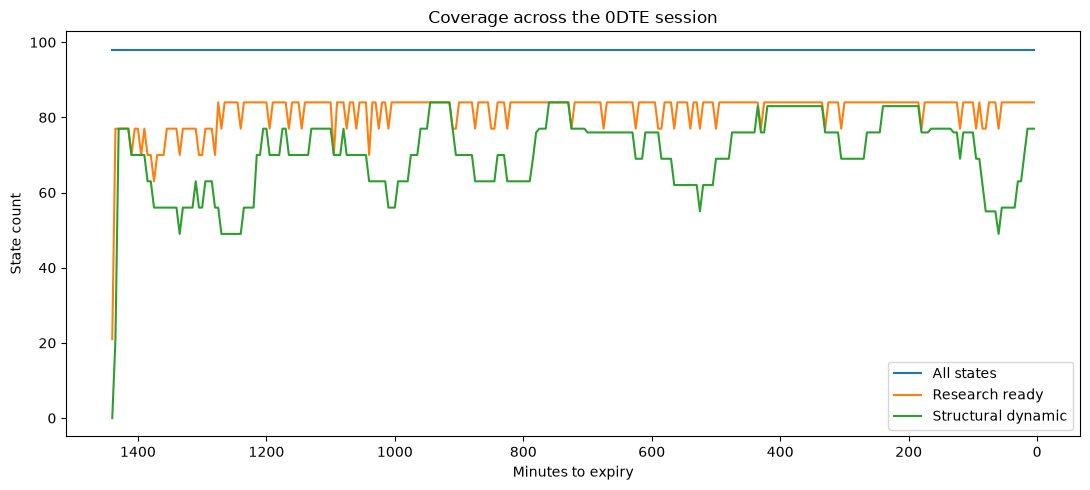

In [23]:
if "minutes_to_expiry" in features.columns:
    session_progress = (
        features.groupby("minutes_to_expiry")
        .agg(
            states=("state_id", "size"),
            research_ready=("state_research_ready", lambda s: int(s.fillna(False).sum())),
            structural_dynamic=("structural_dynamic_features_ready", lambda s: int(s.fillna(False).sum())),
        )
        .reset_index()
        .sort_values("minutes_to_expiry", ascending=False)
    )

    display(session_progress.head(20))

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(session_progress["minutes_to_expiry"], session_progress["states"], label="All states")
    ax.plot(session_progress["minutes_to_expiry"], session_progress["research_ready"], label="Research ready")
    ax.plot(session_progress["minutes_to_expiry"], session_progress["structural_dynamic"], label="Structural dynamic")
    ax.invert_xaxis()
    ax.set_xlabel("Minutes to expiry")
    ax.set_ylabel("State count")
    ax.set_title("Coverage across the 0DTE session")
    ax.legend()
    plt.tight_layout()
    plt.show()

## 17. Inventory report objects

In [24]:
inventory_report = {
    "overview": overview,
    "asset_counts": asset_counts,
    "expiry_counts": expiry_counts,
    "dtypes": dtype_inventory,
    "missingness": missingness,
    "readiness": readiness_summary,
    "numeric_summary": numeric_summary,
    "constant_features": constant_summary,
    "irregular_gaps": gap_summary,
    "availability_by_asset": availability_by_asset,
}

print("Inventory report sections:")
for name, frame in inventory_report.items():
    print(f"  {name:<24} {len(frame):>6,} rows")

Inventory report sections:
  overview                      8 rows
  asset_counts                  7 rows
  expiry_counts                14 rows
  dtypes                      148 rows
  missingness                 148 rows
  readiness                    16 rows
  numeric_summary             105 rows
  constant_features             8 rows
  irregular_gaps                0 rows
  availability_by_asset         7 rows


## 18. Interpretation checklist

Before moving to `02_market_distributions.ipynb`, verify:

1. uniqueness checks are zero;
2. expected assets have expected state counts;
3. missingness is explainable by readiness/history rather than unexplained corruption;
4. no candidate numeric features contain infinities;
5. no important features are constant or nearly constant;
6. timestamp gaps are understood;
7. readiness degradation clusters are understood;
8. delta-smile sparsity is materially higher than fixed-moneyness sparsity where expected;
9. L2-instability features begin only after real collection starts;
10. features with unusual tails/scales are identified for dedicated analysis.

No transformation should be promoted into production solely from this notebook.

In [25]:
# Close the read-only connection when finished.
con.close()
print("DuckDB connection closed.")

DuckDB connection closed.
